In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [3]:
ratings = pd.read_csv(
    "../data/raw/ratings.dat",
    sep="::",
    engine="python",
    names=["userId", "movieId", "rating", "timestamp"]
)

ratings.head()

,userId,movieId,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [4]:
movies = pd.read_csv(
    "../data/raw/movies.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["movieId", "title", "genres"]
)

movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
users = pd.read_csv(
    "../data/raw/users.dat",
    sep="::",
    engine="python",
    names=["userId", "gender", "age", "occupation", "zip-code"]
)

users.head()

,userId,gender,age,occupation,zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [6]:
print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Users:", users.shape)

Ratings: (1000209, 4)
Movies: (3883, 3)
Users: (6040, 5)


In [7]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   userId     1000209 non-null  int64
 1   movieId    1000209 non-null  int64
 2   rating     1000209 non-null  int64
 3   timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


In [8]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  3883 non-null   int64 
 1   title    3883 non-null   object
 2   genres   3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB


In [9]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   userId      6040 non-null   int64 
 1   gender      6040 non-null   object
 2   age         6040 non-null   int64 
 3   occupation  6040 non-null   int64 
 4   zip-code    6040 non-null   object
dtypes: int64(3), object(2)
memory usage: 236.1+ KB


In [10]:
ratings.describe()

,userId,movieId,rating,timestamp
count,1.000209e+06,1.000209e+06,1.000209e+06,1.000209e+06
mean,3.024512e+03,1.865540e+03,3.581564e+00,9.722437e+08
std,1.728413e+03,1.096041e+03,1.117102e+00,1.215256e+07
min,1.000000e+00,1.000000e+00,1.000000e+00,9.567039e+08
25%,1.506000e+03,1.030000e+03,3.000000e+00,9.653026e+08
50%,3.070000e+03,1.835000e+03,4.000000e+00,9.730180e+08
75%,4.476000e+03,2.770000e+03,4.000000e+00,9.752209e+08
max,6.040000e+03,3.952000e+03,5.000000e+00,1.046455e+09


In [11]:
print("Ratings missing values:")
print(ratings.isnull().sum())

print("\nMovies missing values:")
print(movies.isnull().sum())

print("\nUsers missing values:")
print(users.isnull().sum())

Ratings missing values:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Movies missing values:
movieId    0
title      0
genres     0
dtype: int64

Users missing values:
userId        0
gender        0
age           0
occupation    0
zip-code      0
dtype: int64


In [12]:
print("Duplicate ratings:", ratings.duplicated().sum())
print("Duplicate movies:", movies.duplicated().sum())
print("Duplicate users:", users.duplicated().sum())

Duplicate ratings: 0
Duplicate movies: 0
Duplicate users: 0


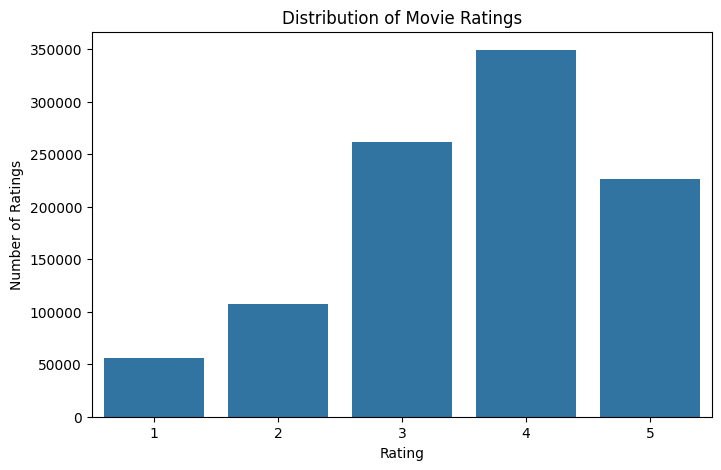

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

In [14]:
ratings["rating"].mean()

np.float64(3.581564453029317)

In [15]:
ratings["rating"].value_counts().sort_index()

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

In [16]:
movie_rating_counts = (
    ratings.groupby("movieId")
    .size()
    .sort_values(ascending=False)
)

movie_rating_counts.head(10)

movieId
2858    3428
260     2991
1196    2990
1210    2883
480     2672
2028    2653
589     2649
2571    2590
1270    2583
593     2578
dtype: int64

In [17]:
most_rated_movies = (
    ratings.groupby("movieId")
    .agg(
        rating_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .reset_index()
    .merge(movies[["movieId", "title"]], on="movieId")
    .sort_values("rating_count", ascending=False)
)

most_rated_movies.head(10)

,movieId,rating_count,average_rating,title
2651,2858,3428,4.317386,American Beauty (1999)
253,260,2991,4.453694,Star Wars: Episode IV - A New Hope (1977)
1106,1196,2990,4.292977,Star Wars: Episode V - The Empire Strikes Back...
1120,1210,2883,4.022893,Star Wars: Episode VI - Return of the Jedi (1983)
466,480,2672,3.763847,Jurassic Park (1993)
1848,2028,2653,4.337354,Saving Private Ryan (1998)
575,589,2649,4.058513,Terminator 2: Judgment Day (1991)
2374,2571,2590,4.315830,"Matrix, The (1999)"
1178,1270,2583,3.990321,Back to the Future (1985)
579,593,2578,4.351823,"Silence of the Lambs, The (1991)"


In [18]:
popular_movies = most_rated_movies[
    most_rated_movies["rating_count"] >= 100
]

popular_movies.sort_values(
    "average_rating",
    ascending=False
).head(10)

,movieId,rating_count,average_rating,title
1839,2019,628,4.560510,Seven Samurai (The Magnificent Seven) (Shichin...
309,318,2227,4.554558,"Shawshank Redemption, The (1994)"
802,858,2223,4.524966,"Godfather, The (1972)"
708,745,657,4.520548,"Close Shave, A (1995)"
49,50,1783,4.517106,"Usual Suspects, The (1995)"
513,527,2304,4.510417,Schindler's List (1993)
1066,1148,882,4.507937,"Wrong Trousers, The (1993)"
861,922,470,4.491489,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950)
1108,1198,2514,4.477725,Raiders of the Lost Ark (1981)
843,904,1050,4.476190,Rear Window (1954)


In [19]:
ratings_per_user = (
    ratings.groupby("userId")
    .size()
)

ratings_per_user.describe()

count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
dtype: float64

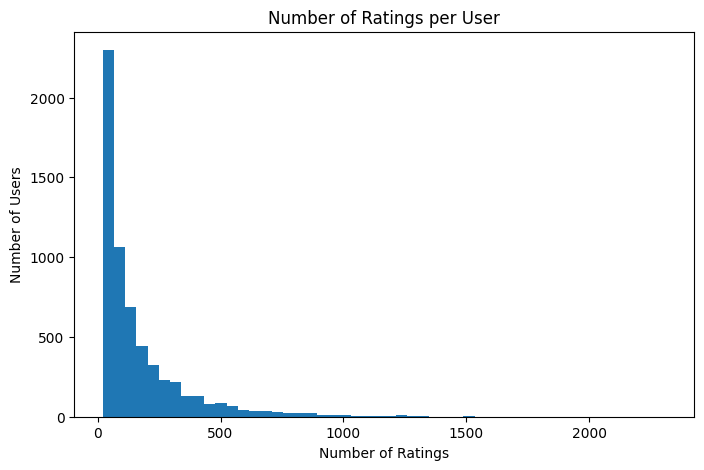

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(
    ratings_per_user,
    bins=50
)

plt.title("Number of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.show()

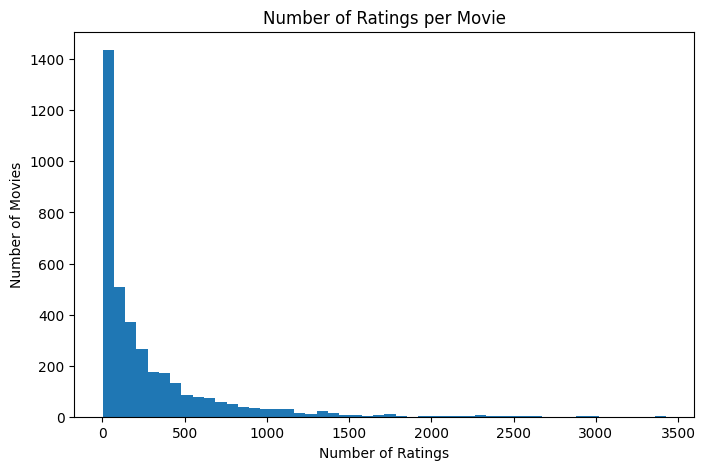

In [21]:
ratings_per_movie = (
    ratings.groupby("movieId")
    .size()
)

plt.figure(figsize=(8, 5))

plt.hist(
    ratings_per_movie,
    bins=50
)

plt.title("Number of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")

plt.show()

In [22]:
genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

genre_counts

genres
Drama          1603
Comedy         1200
Action          503
Thriller        492
Romance         471
Horror          343
Adventure       283
Sci-Fi          276
Children's      251
Crime           211
War             143
Documentary     127
Musical         114
Mystery         106
Animation       105
Fantasy          68
Western          68
Film-Noir        44
Name: count, dtype: int64

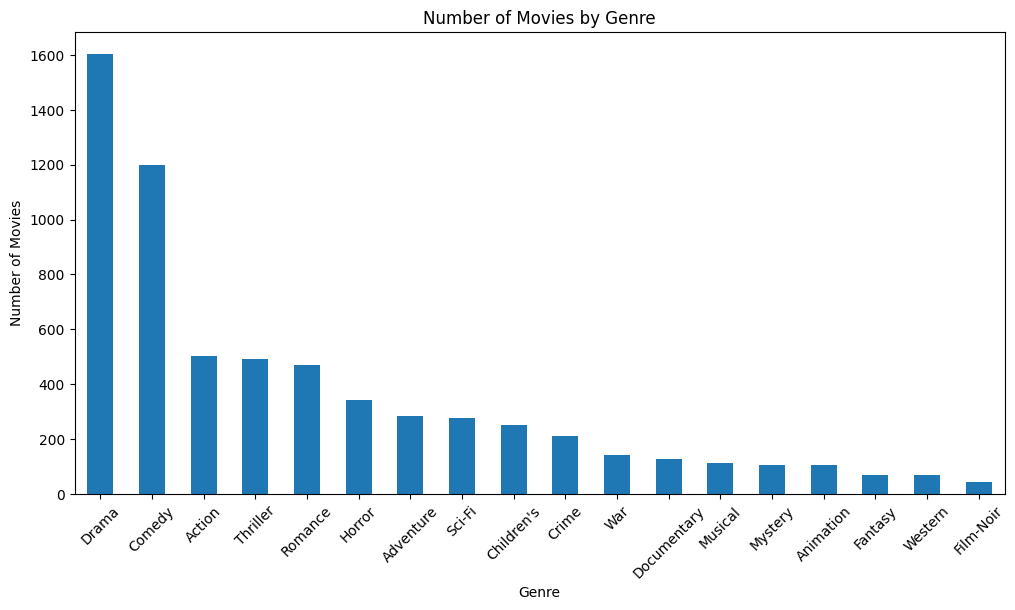

In [23]:
plt.figure(figsize=(12, 6))

genre_counts.plot(kind="bar")

plt.title("Number of Movies by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")

plt.xticks(rotation=45)

plt.show()

In [24]:
movie_ratings = ratings.merge(
    movies,
    on="movieId",
    how="left"
)

movie_ratings.head()

,userId,movieId,rating,timestamp,title,genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [25]:
num_users = ratings["userId"].nunique()
num_movies = ratings["movieId"].nunique()

total_possible_ratings = num_users * num_movies
actual_ratings = len(ratings)

sparsity = 1 - (actual_ratings / total_possible_ratings)

print("Users:", num_users)
print("Movies:", num_movies)
print("Actual ratings:", actual_ratings)
print("Possible ratings:", total_possible_ratings)
print("Sparsity:", sparsity)
print("Sparsity %:", sparsity * 100)

Users: 6040
Movies: 3706
Actual ratings: 1000209
Possible ratings: 22384240
Sparsity: 0.9553163743776871
Sparsity %: 95.53163743776871
